# ENGE707 Kaggle Competition - Assessment 3

## Task 1 : Dataset Exploration and Understanding

In [2]:
"""01 Data Exploration: Dataset Structure

Inspects the structure of the training and test data before any modelling.
Each check prints a PASS/FAIL result so the output can be used as evidence in the report (Task 1.2).

Run from the project folder:  python 01_data_structure.py
"""

# %% Configuration
# All paths are defined once here. Adjust `DATA_DIR` to wherever the Kaggle files are stored.
from pathlib import Path
from collections import Counter

import pandas as pd
from PIL import Image

DATA_DIR = Path("data")                      # folder containing train/, test/ and the CSV files
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
SAMPLE_SUB_CSV = DATA_DIR / "sample_submission.csv"
OUTPUT_DIR = Path("outputs")                 # where summary tables are saved for later scripts
OUTPUT_DIR.mkdir(exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
EXPECTED_CLASSES = {"CatEye", "DogEye", "CatFace", "DogFace",
                    "CatMouth", "DogMouth", "CatNose", "DogNose"}

print(f"Working directory: {Path.cwd()}")
missing = []
for p in [TRAIN_DIR, TEST_DIR, TRAIN_CSV, SAMPLE_SUB_CSV]:
    print(f"{'found  ' if p.exists() else 'MISSING'}  {p.resolve()}")
    if not p.exists():
        missing.append(p)
if missing:
    raise SystemExit("Some paths are missing. Set DATA_DIR (and TRAIN_CSV if the label file "
                     "has a different name) at the top of this script, then run it again.")

# %% 1. Load the CSV files
# `image_id` is read as text (`dtype=str`) so zero-padded IDs such as `00001` keep their leading zeros and match the filenames.
train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
sub_df = pd.read_csv(SAMPLE_SUB_CSV, dtype={"image_id": str})

print("train_labels.csv")
print(f"  shape: {train_df.shape}, columns: {list(train_df.columns)}")
print(train_df.head())

print("sample_submission.csv")
print(f"  shape: {sub_df.shape}, columns: {list(sub_df.columns)}")
print(sub_df.head())

# %% 2. Folder inventory
# Counts every file in each folder and groups them by extension, so unexpected files (hidden system files, non-images) are visible.
def inventory(folder):
    # Searches subfolders too, since Kaggle zips often unpack as train/train/...
    files = [f for f in folder.rglob("*") if f.is_file()]
    images = [f for f in files if f.suffix.lower() in IMAGE_EXTENSIONS]
    other = [f for f in files if f.suffix.lower() not in IMAGE_EXTENSIONS]
    subfolders = [d for d in folder.rglob("*") if d.is_dir()]
    return files, images, other, subfolders

folder_info = {}
for name, folder in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    if not folder.is_dir():
        raise SystemExit(f"Folder not found: {folder.resolve()}\n"
                         f"Set DATA_DIR at the top of this script to the folder containing train/ and test/.")
    files, images, other, subfolders = inventory(folder)
    folder_info[name] = images
    print(f"[{name}/]  ({folder.resolve()})")
    print(f"  total files:       {len(files)}")
    print(f"  image files:       {len(images)}")
    print(f"  extensions:        {dict(Counter(f.suffix.lower() for f in files))}")
    print(f"  non-image files:   {len(other)} {[f.name for f in other[:10]]}")
    print(f"  subfolders:        {len(subfolders)} {[str(d.relative_to(folder)) for d in subfolders[:10]]}")
    print(f"  example files:     {sorted(str(f.relative_to(folder)) for f in images)[:5]}")
    if not images:
        raise SystemExit(f"No image files found in {folder.resolve()}. "
                         f"Check DATA_DIR and the file extensions listed above.")

# %% 3. Training labels against training images
# Matches filenames (without extension) to `image_id` in both directions.
train_files = {f.stem: f for f in folder_info["train"]}
label_ids = set(train_df["image_id"])

labels_without_image = label_ids - set(train_files)
images_without_label = set(train_files) - label_ids
duplicate_ids = train_df["image_id"][train_df["image_id"].duplicated()].tolist()
unexpected_classes = set(train_df["class"].unique()) - EXPECTED_CLASSES

def check(description, passed, detail=""):
    print(f"[{'PASS' if passed else 'FAIL'}] {description} {detail}")

check("Row count matches image count:", len(train_df) == len(train_files),
      f"({len(train_df)} rows, {len(train_files)} images)")
check("Every label has a matching image:", not labels_without_image,
      f"({len(labels_without_image)} missing) {sorted(labels_without_image)[:5]}")
check("Every image has a label:", not images_without_label,
      f"({len(images_without_label)} unlabelled) {sorted(images_without_label)[:5]}")
check("All image_id values are unique:", not duplicate_ids,
      f"({len(duplicate_ids)} duplicates) {duplicate_ids[:5]}")
check("All class values are one of the eight expected classes:", not unexpected_classes,
      f"{sorted(unexpected_classes)}")
check("No missing values in train_labels.csv:", train_df.isna().sum().sum() == 0)

print("\nClasses found:", sorted(train_df["class"].unique()))

# %% 4. Test images against the sample submission
# Also inspects what the `class` column of the sample submission contains, which settles the exact label spelling expected by the grader (for example `DogEye` vs `DogEyes`).
test_files = {f.stem: f for f in folder_info["test"]}
sub_ids = set(sub_df["image_id"])

check("Submission row count matches test image count:", len(sub_df) == len(test_files),
      f"({len(sub_df)} rows, {len(test_files)} images)")
check("Every submission ID has a test image:", not (sub_ids - set(test_files)),
      f"({len(sub_ids - set(test_files))} missing) {sorted(sub_ids - set(test_files))[:5]}")
check("Every test image appears in the submission:", not (set(test_files) - sub_ids),
      f"({len(set(test_files) - sub_ids)} absent) {sorted(set(test_files) - sub_ids)[:5]}")
check("Submission IDs are unique:", not sub_df["image_id"].duplicated().any())

print("\nValues in sample_submission 'class' column:")
print(sub_df["class"].value_counts())
print("\nValues NOT in the training label set:",
      sorted(set(sub_df["class"].astype(str)) - EXPECTED_CLASSES))

# %% #ID ranges and overlap
# Both sets may number from `00001`, so the same ID can refer to different images in `train/` and `test/`. Paths must always include the folder.
def id_summary(ids, name):
    nums = sorted(int(i) for i in ids)
    gaps = (nums[-1] - nums[0] + 1) - len(nums)
    print(f"{name}: min {nums[0]}, max {nums[-1]}, count {len(nums)}, gaps in range {gaps}, "
          f"ID string lengths {sorted({len(i) for i in ids})}")

id_summary(label_ids, "train")
id_summary(sub_ids, "test ")
overlap = label_ids & sub_ids
print(f"IDs shared between train and test: {len(overlap)} (different images, same ID string)")

# %% 5. Basic image properties
# Reads only the image header (fast), recording format, colour mode and dimensions for every image.
# Files that fail to open are recorded rather than stopping the loop. The table is saved for reuse in the data quality section.
def image_properties(files, split):
    records = []
    for image_id, path in files.items():
        try:
            with Image.open(path) as img:
                records.append({"split": split, "image_id": image_id, "file": path.name,
                                "format": img.format, "mode": img.mode,
                                "width": img.width, "height": img.height, "error": None})
        except Exception as e:
            records.append({"split": split, "image_id": image_id, "file": path.name,
                            "format": None, "mode": None, "width": None, "height": None,
                            "error": type(e).__name__})
    return records

props = pd.DataFrame(image_properties(train_files, "train") + image_properties(test_files, "test"))
props.to_csv(OUTPUT_DIR / "image_properties.csv", index=False)

for split, g in props.groupby("split"):
    print(f"[{split}]  images: {len(g)}, failed to open: {g['error'].notna().sum()}")
    print(f"  formats: {g['format'].value_counts(dropna=False).to_dict()}")
    print(f"  modes:   {g['mode'].value_counts(dropna=False).to_dict()}")
    print(f"  width  min/median/max: {g['width'].min()} / {g['width'].median()} / {g['width'].max()}")
    print(f"  height min/median/max: {g['height'].min()} / {g['height'].median()} / {g['height'].max()}")
    print(f"  distinct (width, height) sizes: {g.groupby(['width', 'height']).ngroups}")

# %% 6. Summary table for the report

def describe(split, n_csv_rows, labelled, use):
    g = props[props["split"] == split]
    return {"Folder": f"{split}/",
            "Images": len(g),
            "CSV rows": n_csv_rows,
            "Format(s)": ", ".join(sorted(g["format"].dropna().unique())),
            "Colour mode(s)": ", ".join(sorted(g["mode"].dropna().unique())),
            "Size range (W x H)": f"{int(g['width'].min())}x{int(g['height'].min())} to "
                                  f"{int(g['width'].max())}x{int(g['height'].max())}",
            "Labelled": labelled,
            "Used for": use}

summary = pd.DataFrame([
    describe("train", len(train_df), "Yes (train_labels.csv)", "Training and validation"),
    describe("test", len(sub_df), "No", "Kaggle predictions only"),
])
summary.to_csv(OUTPUT_DIR / "dataset_structure_summary.csv", index=False)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(summary.to_string(index=False))

Working directory: /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/train
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/test
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/train_labels.csv
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/sample_submission.csv
train_labels.csv
  shape: (63660, 2), columns: ['image_id', 'class']
  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogFace
3    00004   DogNose
4    00005   DogNose
sample_submission.csv
  shape: (29443, 2), columns: ['image_id', 'class']
  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogM

## Class Distribution

Rows in train_labels.csv: 63660
Labels with a matching image: 63660 (dropped 0)

Images per class
          Images  Share (%)
class                      
CatEye     13884       21.8
DogEye     11580       18.2
CatFace     6942       10.9
DogFace     5790        9.1
CatMouth    6942       10.9
DogMouth    5790        9.1
CatNose     6942       10.9
DogNose     5790        9.1
Total      63660      100.0

Largest class(es):  CatEye (13884)
Smallest class(es): DogFace, DogMouth, DogNose (5790)
Imbalance ratio (largest / smallest): 2.40

By species:
  Cat     34710  (54.5%)
  Dog     28950  (45.5%)

By part:
  Eye     25464  (40.0%)
  Mouth   12732  (20.0%)
  Face    12732  (20.0%)
  Nose    12732  (20.0%)

Source-photo pattern check
  Cat: Face=6942, Mouth=6942, Nose=6942, Eye=13884  ->  Face=Mouth=Nose: True, Eye = 2 x Face: True
  Dog: Face=5790, Mouth=5790, Nose=5790, Eye=11580  ->  Face=Mouth=Nose: True, Eye = 2 x Face: True

Saved chart to outputs/figures/class_distribution.png


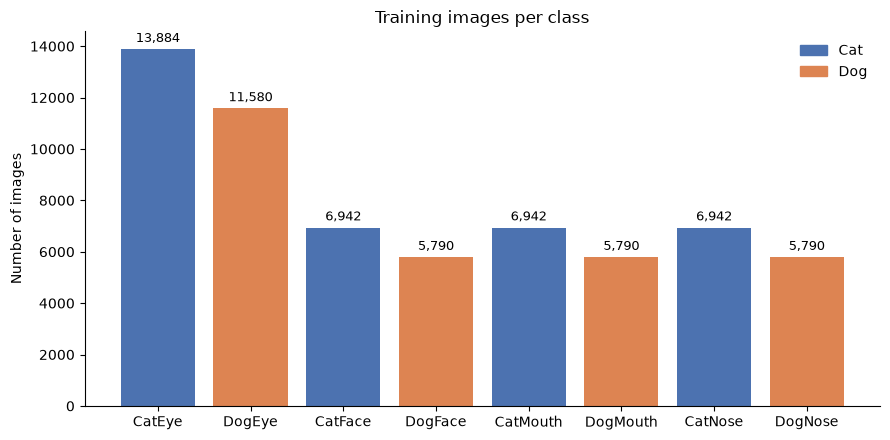

In [4]:
"""02 Data Exploration: Class Distribution

Counts the images in each class and checks how balanced the dataset is (report Tasks 1.3 and 1.4).
Counts are taken from train_labels.csv and confirmed against the image files that actually exist,
so the reported numbers reflect usable training images.

Run from the project folder:  python 02_class_distribution.py
Requires: pandas, matplotlib
"""

# %% Configuration
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")                      # same setting as 01_data_structure.py
TRAIN_DIR = DATA_DIR / "train"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
CLASS_ORDER = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]

train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
print(f"Rows in {TRAIN_CSV.name}: {len(train_df)}")

# %% 1. Keep only labels whose image file exists
# If 01_data_structure.py reported every label matched an image, nothing is dropped here.
existing_ids = {f.stem for f in TRAIN_DIR.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS}
train_df["has_image"] = train_df["image_id"].isin(existing_ids)
print(f"Labels with a matching image: {train_df['has_image'].sum()} "
      f"(dropped {(~train_df['has_image']).sum()})")
df = train_df[train_df["has_image"]].copy()

# %% 2. Images per class
counts = df["class"].value_counts().reindex(CLASS_ORDER)
table = pd.DataFrame({"Images": counts, "Share (%)": (counts / counts.sum() * 100).round(1)})
table.loc["Total"] = [counts.sum(), 100.0]
table["Images"] = table["Images"].astype(int)
print("\nImages per class")
print(table.to_string())
table.to_csv(OUTPUT_DIR / "class_counts.csv")

# %% 3. Balance measures
# The eight classes combine species (Cat/Dog) and facial part (Eye/Face/Mouth/Nose),
# so each factor is summarised separately as well.
df["species"] = df["class"].str[:3]
df["part"] = df["class"].str[3:]

ratio = counts.max() / counts.min()
# Lists every class sharing the max or min, since several classes may tie.
print(f"\nLargest class(es):  {', '.join(counts[counts == counts.max()].index)} ({counts.max()})")
print(f"Smallest class(es): {', '.join(counts[counts == counts.min()].index)} ({counts.min()})")
print(f"Imbalance ratio (largest / smallest): {ratio:.2f}")

for factor in ["species", "part"]:
    s = df[factor].value_counts()
    print(f"\nBy {factor}:")
    for k, v in s.items():
        print(f"  {k:<6} {v:>6}  ({v / len(df) * 100:.1f}%)")

# %% 4. Check the source-photo pattern
# Hypothesis: each source photo yields one face, one mouth, one nose and two eye crops.
# If true, within each species Face = Mouth = Nose and Eye = 2 x Face.
print("\nSource-photo pattern check")
for sp in ["Cat", "Dog"]:
    face, mouth, nose, eye = (counts[f"{sp}{p}"] for p in ["Face", "Mouth", "Nose", "Eye"])
    print(f"  {sp}: Face={face}, Mouth={mouth}, Nose={nose}, Eye={eye}  ->  "
          f"Face=Mouth=Nose: {face == mouth == nose}, Eye = 2 x Face: {eye == 2 * face}")

# %% 5. Bar chart for the report
fig, ax = plt.subplots(figsize=(9, 4.5))
colours = ["#4C72B0" if c.startswith("Cat") else "#DD8452" for c in CLASS_ORDER]
bars = ax.bar(CLASS_ORDER, counts.values, color=colours)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3, fontsize=9)
ax.set_ylabel("Number of images")
ax.set_title("Training images per class")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"),
                   plt.Rectangle((0, 0), 1, 1, color="#DD8452")],
          labels=["Cat", "Dog"], frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "class_distribution.png", dpi=200)
print(f"\nSaved chart to {FIG_DIR / 'class_distribution.png'}")
plt.show()